# SC4002 - Lab Assigment

## Import and Configs

In [2]:
import os
import re
import math
import copy
import numpy as np
import pandas as pd
import random
import time

import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import TensorDataset, DataLoader, Dataset
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import gensim.downloader as api

import nltk
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

In [3]:
DATA_FOLDER = r"data"
MODEL_FOLDER = r"model"

os.makedirs(DATA_FOLDER, exist_ok=True)
os.makedirs(MODEL_FOLDER, exist_ok=True)

DATASET_FILE = "en-US.jsonl"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
# Fixing seed to remove randomness, for better comparisons
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

In [5]:
RUN_PRETRAINING = True # Run MLM pretraining; if False, reuse the backbone checkpoints in MODEL_FOLDER
USE_MLM = True #Intent classifier uses the MLM-pretrained backbone; if False, the untrained one
RUN_INTENT_TRAINING = False # Train the intent classifier; if False, load its saved checkpoint

# Train the slot filler 
RUN_SLOT_TRAINING = True

In [6]:
os.makedirs(MODEL_FOLDER, exist_ok=True)
UNTRAINED_BACKBONE_PATH = os.path.join(MODEL_FOLDER, "untrained_backbone.pt")
BEST_BACKBONE_PATH = os.path.join(MODEL_FOLDER, "best_backbone.pt")
# Separate intent checkpoints so MLM and no-MLM runs do not overwrite each other
BEST_INTENT_PATH = os.path.join(
    MODEL_FOLDER, "best_intent_mlm.pt" if USE_MLM else "best_intent_no_mlm.pt"
)

## Data Loading

In [7]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir())

Current directory: /Users/shuxuanyu/SC4002-Lab-Assignment
Files here: ['main.ipynb', 'data-analysis.ipynb', 'Group Assignment Instruction.pdf', 'slot-extraction.ipynb', '.gitignore', 'model', '.git', 'data']


In [8]:
df = pd.read_json(os.path.join(DATA_FOLDER,DATASET_FILE), lines=True)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst example:")
print(df.iloc[0])

Dataset shape: (16521, 8)

Columns:
['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id']

First example:
id                                                           0
locale                                                   en-US
partition                                                 test
scenario                                                 alarm
intent                                               alarm_set
utt                            wake me up at five am this week
annot_utt    wake me up at [time : five am] [date : this week]
worker_id                                                    1
Name: 0, dtype: object


In [9]:
# Check the number of examples in each partition
print("Partition distribution:")
print(df["partition"].value_counts())

# Verify the official dataset split sizes
assert (df["partition"] == "train").sum() == 11514
assert (df["partition"] == "dev").sum() == 2033
assert (df["partition"] == "test").sum() == 2974

# Check the number of unique intents
print("\nNumber of unique intents:")
print(df["intent"].nunique())

# Check the number of examples per intent
print("\nExamples per intent:")
display(df["intent"].value_counts().describe())

# Check for missing values
print("\nMissing values:")
print(df[["utt", "annot_utt", "intent", "partition"]].isnull().sum())

# Check whether the dataset contains only en-US
print("\nLocales:")
print(df["locale"].value_counts())

Partition distribution:
partition
train    11514
test      2974
dev       2033
Name: count, dtype: int64

Number of unique intents:
60

Examples per intent:


count      60.000000
mean      275.350000
std       253.817352
min         6.000000
25%       114.750000
50%       183.000000
75%       315.500000
max      1150.000000
Name: count, dtype: float64


Missing values:
utt          0
annot_utt    0
intent       0
partition    0
dtype: int64

Locales:
locale
en-US    16521
Name: count, dtype: int64


In [10]:
train_df = df[df["partition"] == "train"].copy()
val_df = df[df["partition"] == "dev"].copy()
test_df = df[df["partition"] == "test"].copy()

In [11]:
x_train = train_df["utt"].tolist()
y_train = train_df["intent"].tolist()
z_train = train_df["annot_utt"].tolist()

x_val = val_df["utt"].tolist()
y_val = val_df["intent"].tolist()
z_val = val_df["annot_utt"].tolist()

x_test = test_df["utt"].tolist()
y_test = test_df["intent"].tolist()
z_test = test_df["annot_utt"].tolist()

In [12]:
print("Training examples:", len(x_train))
print("Validation examples:", len(x_val))
print("Test examples:", len(x_test))

print("\nExample utterance:", x_train[0])
print("Example intent:", y_train[0])
print("Example annotated utterance:", z_train[0])

Training examples: 11514
Validation examples: 2033
Test examples: 2974

Example utterance: wake me up at nine am on friday
Example intent: alarm_set
Example annotated utterance: wake me up at [time : nine am] on [date : friday]


In [13]:
glove = api.load("glove-wiki-gigaword-100")

In [14]:
# Check vocabulary size
print("Vocabulary size:", len(glove.index_to_key))

# Check embedding dimension
print("Embedding dimension:", glove.vector_size)

# Get the vector for a word
print("Vector for 'music':")
print(glove["music"])

Vocabulary size: 400000
Embedding dimension: 100
Vector for 'music':
[ 1.2705e-01  3.7253e-01  2.3076e-01 -1.0727e-01  1.4273e+00  7.7990e-01
 -5.5009e-02 -1.8909e-01 -4.2828e-01  2.8443e-01  1.1920e-01 -6.1978e-01
 -3.9817e-01  1.9127e-01 -3.2098e-01 -2.4116e-01  6.0927e-01 -3.5765e-01
  2.0159e-01  9.1107e-01 -4.8977e-01 -2.8970e-01  1.0098e+00 -6.6149e-01
  7.0414e-02  1.3353e-01  4.2234e-01 -8.0188e-02  1.0722e+00  2.6426e-01
 -7.3982e-01  6.4958e-01 -4.8367e-01  8.5837e-01 -3.9008e-01 -1.3020e-01
  2.2331e-01  2.0818e-01 -4.7260e-01 -1.7275e+00  3.7209e-01  5.5544e-01
 -8.9025e-01  8.7442e-01 -2.9063e-01 -7.1175e-01 -3.3437e-01 -4.1141e-01
  9.9049e-01 -4.6207e-01 -2.5777e-01  4.9513e-02 -2.2242e-01 -3.3757e-01
 -1.5677e-01 -2.9576e+00 -5.8878e-01  2.2432e-01  1.6375e+00  1.0263e+00
  8.9573e-01  1.3718e+00 -3.7709e-01 -8.2095e-02  1.6339e-01 -2.5294e-01
  1.0987e+00 -2.0032e-03  7.9235e-01 -2.9403e-01 -2.6906e-01  2.3123e-01
  3.3826e-01  1.7150e-01 -3.5479e-01 -1.3497e-01  6.441

In [15]:
token_pattern = re.compile(r'\w+|[^\w\s]')

def tokenize_with_offsets(text):
    matches = token_pattern.finditer(text)
    return [(m.group().lower(), m.start(), m.end()) for m in matches]

def tokenize(text):
    return [token for token, _, _ in tokenize_with_offsets(text)]

In [16]:
def check_glove_coverage(texts, glove):
    all_tokens = [
        token
        for text in texts
        for token in tokenize(text)
    ]

    unique_tokens = set(all_tokens)
    known_tokens = {token for token in unique_tokens if token in glove}

    total_tokens = len(all_tokens)
    total_unique = len(unique_tokens)
    known_count = sum(token in glove for token in all_tokens)

    print(f"Total tokens: {total_tokens:,}")
    print(f"Unique words: {total_unique:,}")
    print(f"Unique words covered: {len(known_tokens):,}")
    print(f"Unique words OOV: {total_unique - len(known_tokens):,}")

    print(f"\nUnique-word coverage: {len(known_tokens) / total_unique * 100:.2f}%")
    print(f"Token coverage: {known_count / total_tokens * 100:.2f}%")

    oov_words = sorted(unique_tokens - known_tokens)
    print("\nFirst 30 OOV words:")
    print(oov_words[:30])

In [17]:
# Check each split
print("TRAINING SET")
check_glove_coverage(x_train, glove)

print("\nVALIDATION SET")
check_glove_coverage(x_val, glove)

print("\nTEST SET")
check_glove_coverage(x_test, glove)

TRAINING SET
Total tokens: 83,008
Unique words: 5,144
Unique words covered: 4,963
Unique words OOV: 181

Unique-word coverage: 96.48%
Token coverage: 99.67%

First 30 OOV words:
['altucher', 'apahelp', 'apig', 'applebees', 'badpho', 'bardonia', 'bbcnews', 'beanos', 'beiber', 'beibers', 'bestbuy', 'blahblah', 'bobburgers', 'brexit', 'brightener', 'btaxes', 'burmuda', 'calone', 'capabara', 'capuccino', 'channin', 'chhana', 'cnncom', 'comcastcom', 'comcasts', 'companyname', 'dalls', 'dancom', 'dbell', 'ddlj']

VALIDATION SET
Total tokens: 14,522
Unique words: 2,088
Unique words covered: 2,052
Unique words OOV: 36

Unique-word coverage: 98.28%
Token coverage: 99.70%

First 30 OOV words:
['alzacz', 'arrahman', 'ashmit', 'bakey', 'brexit', 'burmuda', 'capricorns', 'culotte', 'demonetisation', 'dooa', 'eggroll', 'enalen', 'erosser', 'finlee', 'gavenda', 'gbaby', 'harrypotter', 'iliza', 'metion', 'obaba', 'orevena', 'palhunik', 'phillyx', 'reveca', 'rihana', 'schleshinger', 'swatishs', 'tiangl

In [18]:
# Special token IDs
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
MASK_TOKEN = "<MASK>"

PAD_ID = 0
UNK_ID = 1
MASK_ID = 2

# Tokenize the training utterances
tokenized_x_train = [tokenize(text) for text in x_train]

# Build vocabulary using the training set
vocab_words = sorted({
    token
    for tokens in tokenized_x_train
    for token in tokens
})

# Create word-to-ID mapping
word_to_id = {
    PAD_TOKEN: PAD_ID,
    UNK_TOKEN: UNK_ID,
    MASK_TOKEN: MASK_ID
}

for word in vocab_words:
    if word not in word_to_id:
        word_to_id[word] = len(word_to_id)

# Create reverse mapping
id_to_word = {idx: word for word, idx in word_to_id.items()}

print("Training vocabulary size (incl. PAD/UNK/MASK):", len(word_to_id))
print("Training tokens missing from GloVe:", sum(word not in glove for word in vocab_words))

Training vocabulary size (incl. PAD/UNK/MASK): 5147
Training tokens missing from GloVe: 181


In [19]:
USE_LEMMA_FALLBACK = False

lemmatizer = WordNetLemmatizer()

def lemmatize_token(token):
    # Try the noun form first (plurals), then the verb form (tenses)
    lemma = lemmatizer.lemmatize(token, pos='n')
    if lemma == token:
        lemma = lemmatizer.lemmatize(token, pos='v')
    return lemma

def token_to_id(token, word_to_id, use_lemma):
    # Known words keep their own ID; only unseen words fall back to their lemma
    if token in word_to_id:
        return word_to_id[token]
    if use_lemma:
        lemma = lemmatize_token(token)
        if lemma in word_to_id:
            return word_to_id[lemma]
    return UNK_ID

In [20]:
embedding_dim = glove.vector_size
vocab_size = len(word_to_id)

rng = np.random.default_rng(SEED)

embedding_matrix = rng.normal(
    0, 0.1, (vocab_size, embedding_dim)
).astype(np.float32)

embedding_matrix[PAD_ID] = 0

for word, idx in word_to_id.items():
    if word in glove:
        embedding_matrix[idx] = glove[word]

print("Embedding matrix shape:", embedding_matrix.shape)
print("Padding vector:", embedding_matrix[PAD_ID])
print("Unknown vector shape:", embedding_matrix[UNK_ID].shape)
print("Words missing from GloVe:",
      sum(word not in glove for word in vocab_words))


Embedding matrix shape: (5147, 100)
Padding vector: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0.]
Unknown vector shape: (100,)
Words missing from GloVe: 181


In [21]:
max_train_len = max(len(tokens) for tokens in tokenized_x_train)
max_len = max(64, max_train_len)
print("Longest training sentence:", max_train_len)
print("Padding length:", max_len)

Longest training sentence: 35
Padding length: 64


In [22]:
intents = sorted(set(y_train))

intent_to_id = {
    intent: idx
    for idx, intent in enumerate(intents)
}

id_to_intent = {
    idx: intent
    for intent, idx in intent_to_id.items()
}

num_classes = len(intent_to_id)

print("Number of intent classes:", num_classes)
print("\nExample mappings:")
for intent in intents[:5]:
    print(f"{intent} -> {intent_to_id[intent]}")

Number of intent classes: 60

Example mappings:
alarm_query -> 0
alarm_remove -> 1
alarm_set -> 2
audio_volume_down -> 3
audio_volume_mute -> 4


In [23]:
slot_pattern = re.compile(r'\[\s*([^:\[\]]+?)\s*:\s*([^\[\]]*?)\]')
SLOT_PAD_ID = -100  

def parse_annotated_utterance(utt, annot_utt):
    spans = []
    plain_text = ''
    last_end = 0

    for match in slot_pattern.finditer(annot_utt):
        plain_text += annot_utt[last_end:match.start()]
        slot_type = match.group(1).strip()
        slot_value = match.group(2)
        start = len(plain_text)
        plain_text += slot_value
        spans.append({
            'type': slot_type,
            'start': start,
            'end': len(plain_text),
            'text': slot_value
        })
        last_end = match.end()

    plain_text += annot_utt[last_end:]
    if plain_text != utt:
        raise ValueError(f"Slot annotation does not match utterance: {utt!r}")

    return spans


In [24]:
def make_aligned_tokens(utt, spans):
    tags = []
    offsets = []
    prev_slot = None

    for word, start, end in tokenize_with_offsets(utt):
        current_slot = None
        for i, span in enumerate(spans):
            if start < span['end'] and end > span['start']:
                if start < span['start'] or end > span['end']:
                    raise ValueError(f"A token cuts across a slot boundary: {utt!r}")
                if current_slot is not None:
                    raise ValueError(f"A token overlaps two slots: {utt!r}")
                current_slot = i

        if current_slot is None:
            tags.append('O')
        else:
            prefix = 'I' if current_slot == prev_slot else 'B'
            tags.append(f"{prefix}-{spans[current_slot]['type']}")

        offsets.append((start, end))
        prev_slot = current_slot

    for span in spans:
        if not any(s >= span['start'] and e <= span['end'] for s, e in offsets):
            raise ValueError(f"Could not align slot {span['text']!r} in {utt!r}")

    return tags, offsets


In [25]:
def prepare_joint_records(split_df):
    records = []
    
    for row_index, row in split_df.iterrows():
        text = row['utt']
        spans = parse_annotated_utterance(text, row['annot_utt'])
        tags, offsets = make_aligned_tokens(text, spans)
        tokens = tokenize(text)

        if len(tokens) != len(tags):
            raise ValueError(f"Token and slot lengths differ at row {row_index}")

        records.append({
            'source_row': int(row_index),
            'utt': text,
            'tokens': tokens,
            'offsets': offsets,
            'gold_spans': spans,
            'slot_tags': tags,
            'intent': row['intent']
        })
    return records


In [26]:
train_records = prepare_joint_records(train_df)
val_records = prepare_joint_records(val_df)
test_records = prepare_joint_records(test_df)

training_slot_types = sorted({span['type'] for row in train_records for span in row['gold_spans']})
slot_tags = ['O']

for slot_type in training_slot_types:
    slot_tags.extend([f'B-{slot_type}', f'I-{slot_type}'])

slot_to_id = {tag: i for i, tag in enumerate(slot_tags)}
id_to_slot = {i: tag for tag, i in slot_to_id.items()}
num_slot_labels = len(slot_to_id)

print('Joint dataset sizes:', len(train_records), len(val_records), len(test_records))
print('Slot types in training:', len(training_slot_types))
print('BIO labels:', num_slot_labels)
print('Example:', train_records[0]['slot_tags'])

Joint dataset sizes: 11514 2033 2974
Slot types in training: 55
BIO labels: 111
Example: ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']


In [27]:
class JointNLUDataset(Dataset):
    def __init__(self, records, word_to_id, intent_to_id, 
                 slot_to_id, max_len, use_lemma=False):
        self.records = records
        self.input_ids = []
        self.attention_masks = []
        self.intent_ids = []
        self.slot_ids = []

        for row in records:
            words = [token_to_id(word, word_to_id, use_lemma) for word in row['tokens']]
            slots = [slot_to_id[tag] for tag in row['slot_tags']]
            if len(words) != len(slots):
                raise ValueError('Token and slot label counts do not match')
            if len(words) > max_len:
                raise ValueError(f"Sentence has {len(words)} tokens, limit is {max_len}")

            padding = max_len - len(words)
            self.input_ids.append(torch.tensor(words + [PAD_ID] * padding))
            self.attention_masks.append(torch.tensor([1] * len(words) + [0] * padding, 
                                                     dtype=torch.bool))
            self.intent_ids.append(torch.tensor(intent_to_id[row['intent']]))
            self.slot_ids.append(torch.tensor(slots + [SLOT_PAD_ID] * padding))

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records[index]
        return {
            'input_ids': self.input_ids[index],
            'attention_mask': self.attention_masks[index],
            'intent_labels': self.intent_ids[index],
            'slot_labels': self.slot_ids[index],
            'utt': row['utt'],
            'offsets': row['offsets'],
            'gold_spans': row['gold_spans'],
            'source_row': row['source_row']
        }

In [28]:
def joint_collate_fn(samples):
    batch = {}
    for key in ('input_ids', 'attention_mask', 'intent_labels', 'slot_labels'):
        batch[key] = torch.stack([item[key] for item in samples])
    for key in ('utt', 'offsets', 'gold_spans', 'source_row'):
        batch[key] = [item[key] for item in samples]
    return batch

In [29]:
train_joint_dataset = JointNLUDataset(train_records, word_to_id, intent_to_id, slot_to_id, max_len, use_lemma=USE_LEMMA_FALLBACK)
val_joint_dataset = JointNLUDataset(val_records, word_to_id, intent_to_id, slot_to_id, max_len, use_lemma=USE_LEMMA_FALLBACK)
test_joint_dataset = JointNLUDataset(test_records, word_to_id, intent_to_id, slot_to_id, max_len, use_lemma=USE_LEMMA_FALLBACK)

In [30]:
batch_size = 64

train_joint_loader = DataLoader(train_joint_dataset, 
                                batch_size=batch_size, 
                                shuffle=True,
                                collate_fn=joint_collate_fn,
                                generator=torch.Generator().manual_seed(SEED))

val_joint_loader = DataLoader(val_joint_dataset, 
                              batch_size=batch_size, 
                              shuffle=False,
                              collate_fn=joint_collate_fn)

test_joint_loader = DataLoader(test_joint_dataset, 
                               batch_size=batch_size, 
                               shuffle=False,
                               collate_fn=joint_collate_fn)

batch = next(iter(train_joint_loader))
print('Input IDs:', batch['input_ids'].shape)
print('Intent labels:', batch['intent_labels'].shape)
print('Slot labels:', batch['slot_labels'].shape)
print('Attention mask:', batch['attention_mask'].shape)

assert batch['input_ids'].shape == batch['slot_labels'].shape
assert torch.equal(batch['slot_labels'] == SLOT_PAD_ID, ~batch['attention_mask'])

Input IDs: torch.Size([64, 64])
Intent labels: torch.Size([64])
Slot labels: torch.Size([64, 64])
Attention mask: torch.Size([64, 64])


In [31]:
def build_vocab(records):
    # Vocabulary from the given training records only
    vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID, MASK_TOKEN: MASK_ID}
    for word in sorted({t for row in records for t in row['tokens']}):
        vocab[word] = len(vocab)
    return vocab

def build_embedding_matrix(vocab):
    matrix_rng = np.random.default_rng(SEED)
    matrix = matrix_rng.normal(0, 0.1, (len(vocab), embedding_dim)).astype(np.float32)
    matrix[PAD_ID] = 0
    for word, idx in vocab.items():
        if word in glove:
            matrix[idx] = glove[word]
    return matrix

def make_loader(records, vocab, use_lemma=False, shuffle=False):
    dataset = JointNLUDataset(records, vocab, intent_to_id, slot_to_id, max_len, use_lemma=use_lemma)
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      collate_fn=joint_collate_fn, generator=generator)

def lemmatize_records(records):
    # Lemmatize model input tokens only; utt, offsets and gold spans stay original
    return [{**row, 'tokens': [lemmatize_token(t) for t in row['tokens']]} for row in records]

# The helpers must reproduce the main pipeline exactly
assert build_vocab(train_records) == word_to_id
assert np.array_equal(build_embedding_matrix(word_to_id), embedding_matrix)
print("Helpers reproduce the main vocabulary and embedding matrix")

Helpers reproduce the main vocabulary and embedding matrix


## Model Architecture

In [32]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=128):
        super().__init__()

        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2)
            * (-math.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        # x shape: (batch_size, sequence_length, d_model)
        return x + self.pe[:, :x.size(1), :]

In [33]:
class BackboneEncoder(nn.Module):
    def __init__(
        self,
        embedding_matrix,
        pad_id,
        max_len=128,
        num_layers=4,
        num_heads=4,
        dim_feedforward=256,
        dropout=0.1,
    ):
        super().__init__()

        embedding_matrix = torch.as_tensor(
            embedding_matrix,
            dtype=torch.float32,
        )

        self.embedding = nn.Embedding.from_pretrained(
            embedding_matrix,
            freeze=True,
            padding_idx=pad_id,
        )

        d_model = embedding_matrix.size(1)

        self.positional_encoding = PositionalEncoding(
            d_model=d_model,
            max_len=max_len,
        )

        self.dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(d_model),
        )

        self.pad_id = pad_id
        self.d_model = d_model

    def forward(self, input_ids, attention_mask):
        x = self.embedding(input_ids)
        x = self.positional_encoding(x)
        x = self.dropout(x)

        padding_mask = ~attention_mask.bool()

        x = self.transformer_encoder(
            x,
            src_key_padding_mask=padding_mask,
        )

        return x

In [34]:
class BackboneReconstructor(nn.Module):
    def __init__(
        self,
        d_model,
        vocab_size,
        num_layers=2,
        num_heads=4,
        dim_feedforward=256,
        dropout=0.1,
    ):
        super().__init__()

        decoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            decoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(d_model),
        )

        self.output_projection = nn.Linear(
            d_model,
            vocab_size,
        )

    def forward(self, hidden_states, attention_mask):
        padding_mask = ~attention_mask.bool()
        x = self.transformer(
            hidden_states,
            src_key_padding_mask=padding_mask,
        )
        logits = self.output_projection(x)

        return logits

In [35]:
class Backbone(nn.Module):
    def __init__(self, encoder, reconstructor):
        super().__init__()

        self.encoder = encoder
        self.reconstructor = reconstructor

    def forward(self, input_ids, attention_mask, labels=None):
        hidden_states = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )

        logits = self.reconstructor(
            hidden_states=hidden_states,
            attention_mask=attention_mask,
        )

        loss = None

        if labels is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                labels.reshape(-1),
                ignore_index=-100,
            )

        return {
            "loss": loss,
            "logits": logits,
        }

In [36]:
class IntentClassifier(nn.Module):
    def __init__(
        self,
        backbone_encoder,
        num_classes,
        num_layers=2,
        nhead=4,
        dim_feedforward=256,
        dropout=0.1,
        pad_id=PAD_ID,
        use_backbone_layers=True,
    ):
        super().__init__()

        # Reuse the existing encoder; do not copy it.
        self.backbone_encoder = backbone_encoder
        self.pad_id = pad_id
        # If False, only the frozen embedding + positional encoding are used
        self.use_backbone_layers = use_backbone_layers

        # Freeze all backbone parameters.
        for param in self.backbone_encoder.parameters():
            param.requires_grad = False

        d_model = self.backbone_encoder.d_model

        if d_model % nhead != 0:
            raise ValueError(
                f"d_model={d_model} must be divisible by nhead={nhead}"
            )

        # Additional Transformer trained for intent classification.
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )

        self.intent_encoder = nn.TransformerEncoder(
            layer,
            num_layers=num_layers,
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, input_ids, attention_mask):
        padding_mask = ~attention_mask.bool()

        # Keep the frozen backbone deterministic, including its dropout.
        with torch.no_grad():
            if self.use_backbone_layers:
                hidden_states = self.backbone_encoder(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                )
            else:
                # GloVe + positional encoding only, as in the old IntentTransformer
                hidden_states = self.backbone_encoder.positional_encoding(
                    self.backbone_encoder.embedding(input_ids)
                )

        # The intent-specific Transformer is trainable.
        hidden_states = self.intent_encoder(
            hidden_states,
            src_key_padding_mask=padding_mask,
        )

        # Masked mean pooling.
        valid_tokens = attention_mask.unsqueeze(-1).to(
            hidden_states.dtype
        )

        pooled = (hidden_states * valid_tokens).sum(dim=1)
        pooled = pooled / valid_tokens.sum(dim=1).clamp(min=1.0)

        logits = self.classifier(self.dropout(pooled))

        return logits

## Pretraining Loop

In [37]:
encoder = BackboneEncoder(
    embedding_matrix=embedding_matrix,
    pad_id=PAD_ID,
    max_len=128,
    num_layers=5,
    num_heads=4,
    dim_feedforward=1024,
    dropout=0.1,
)

reconstructor = BackboneReconstructor(
    d_model=encoder.d_model,
    vocab_size=embedding_matrix.shape[0],
    num_layers=2,
    num_heads=4,
    dim_feedforward=256,
    dropout=0.1,
)

/Users/shuxuanyu/anaconda3/envs/pytorch/lib/python3.11/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


In [38]:
mlm_model = Backbone(
    encoder=encoder,
    reconstructor=reconstructor,
)

In [39]:
MAX_EPOCH = 30
early_stop_patience = 5
best_loss = float("inf")
epochs_without_improvement = 0

train_loss_history = []

In [40]:
def create_mlm_inputs(input_ids, attention_mask, mask_token_id=MASK_ID, mlm_probability=0.15):
    mlm_input_ids = input_ids.clone()
    mlm_labels = input_ids.clone()

    # Only valid, non-padding tokens can be selected
    special_mask = input_ids.eq(PAD_ID)
    eligible_tokens = attention_mask.bool() & ~special_mask

    probability_matrix = torch.full(
        input_ids.shape,
        mlm_probability,
        device=input_ids.device,
    )

    masked_positions = (
        torch.bernoulli(probability_matrix).bool()
        & eligible_tokens
    )

    # Compute loss only at masked positions
    mlm_labels[~masked_positions] = -100

    # Replace selected tokens with the mask token
    mlm_input_ids[masked_positions] = mask_token_id

    return mlm_input_ids, mlm_labels

In [41]:
mlm_model = mlm_model.to(device)

optimizer = optim.AdamW(
    (p for p in mlm_model.parameters() if p.requires_grad),
    lr=1e-3,
    weight_decay=0.01,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.1,
    patience=3,
    min_lr=1e-6,
)

In [42]:
def train_mlm_epoch(
    model,
    dataloader,
    optimizer,
    device,
    mask_token_id,
):
    model.train()

    total_loss = 0.0
    total_batches = 0

    for batch in dataloader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        mlm_input_ids, mlm_labels = create_mlm_inputs(
            input_ids=input_ids,
            attention_mask=attention_mask,
            mask_token_id=mask_token_id,
        )

        # Skip a batch if random masking selected no tokens
        if not (mlm_labels != -100).any():
            continue

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=mlm_input_ids,
            attention_mask=attention_mask,
            labels=mlm_labels,
        )

        loss = outputs["loss"]
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_batches += 1

    if total_batches == 0:
        raise RuntimeError(
            "No masked tokens were selected in any batch."
        )

    return total_loss / total_batches

In [43]:
if RUN_PRETRAINING:
    torch.save(
        {
            k: v.detach().cpu().clone()
            for k, v in mlm_model.encoder.state_dict().items()
        },
        UNTRAINED_BACKBONE_PATH,
    )

    for epoch in range(MAX_EPOCH):
        train_loss = train_mlm_epoch(
            model=mlm_model,
            dataloader=train_joint_loader,
            optimizer=optimizer,
            device=device,
            mask_token_id=MASK_ID,
        )

        train_loss_history.append(train_loss)

        # Update learning rate based on training loss
        scheduler.step(train_loss)

        # Early stopping check
        if train_loss < best_loss:
            best_loss = train_loss
            epochs_without_improvement = 0

            # Save the best model
            best_model_state = {
                k: v.detach().cpu().clone()
                for k, v in mlm_model.state_dict().items()
            }

            torch.save(
                best_model_state,
                BEST_BACKBONE_PATH,
            )
        else:
            epochs_without_improvement += 1

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch [{epoch + 1}/{MAX_EPOCH}] "
            f"| Train MLM Loss: {train_loss:.4f} "
            f"| Best Loss: {best_loss:.4f} "
            f"| LR: {current_lr:.2e}"
        )

        if epochs_without_improvement >= early_stop_patience:
            print(f"Early stopping triggered at epoch {epoch + 1}.")
            break

    # Restore the best model weights
    mlm_model.load_state_dict(best_model_state)

    print(f"Best MLM Loss: {best_loss:.4f}")
else:
    print("Skipping MLM pretraining.")

    # Keep the no-MLM baseline available even if pretraining never ran
    if not os.path.exists(UNTRAINED_BACKBONE_PATH):
        torch.save(
            {
                k: v.detach().cpu().clone()
                for k, v in mlm_model.encoder.state_dict().items()
            },
            UNTRAINED_BACKBONE_PATH,
        )

Epoch [1/30] | Train MLM Loss: 6.3862 | Best Loss: 6.3862 | LR: 1.00e-03
Epoch [2/30] | Train MLM Loss: 5.8766 | Best Loss: 5.8766 | LR: 1.00e-03
Epoch [3/30] | Train MLM Loss: 5.6893 | Best Loss: 5.6893 | LR: 1.00e-03
Epoch [4/30] | Train MLM Loss: 5.5009 | Best Loss: 5.5009 | LR: 1.00e-03
Epoch [5/30] | Train MLM Loss: 5.4185 | Best Loss: 5.4185 | LR: 1.00e-03
Epoch [6/30] | Train MLM Loss: 5.2749 | Best Loss: 5.2749 | LR: 1.00e-03
Epoch [7/30] | Train MLM Loss: 5.1977 | Best Loss: 5.1977 | LR: 1.00e-03
Epoch [8/30] | Train MLM Loss: 5.0444 | Best Loss: 5.0444 | LR: 1.00e-03
Epoch [9/30] | Train MLM Loss: 4.9645 | Best Loss: 4.9645 | LR: 1.00e-03
Epoch [10/30] | Train MLM Loss: 4.8582 | Best Loss: 4.8582 | LR: 1.00e-03
Epoch [11/30] | Train MLM Loss: 4.8121 | Best Loss: 4.8121 | LR: 1.00e-03
Epoch [12/30] | Train MLM Loss: 4.7033 | Best Loss: 4.7033 | LR: 1.00e-03
Epoch [13/30] | Train MLM Loss: 4.5831 | Best Loss: 4.5831 | LR: 1.00e-03
Epoch [14/30] | Train MLM Loss: 4.5360 | Best L

In [44]:
# Load either the best MLM checkpoint or the untrained backbone.
backbone_path = BEST_BACKBONE_PATH if USE_MLM else UNTRAINED_BACKBONE_PATH

if not os.path.exists(backbone_path):
    raise FileNotFoundError(
        f"{backbone_path} not found. Set RUN_PRETRAINING = True to create it."
    )

checkpoint = torch.load(
    backbone_path,
    map_location=device,
    weights_only=True,
)

if USE_MLM:
    # The MLM checkpoint holds the full Backbone (encoder + reconstructor)
    mlm_model.load_state_dict(checkpoint)
    print("Pretrained MLM backbone loaded.")
else:
    # The untrained checkpoint holds the encoder only
    mlm_model.encoder.load_state_dict(checkpoint)
    print("Untrained backbone loaded (no MLM).")

Pretrained MLM backbone loaded.


## Training Loop (Slot Filling)

In [45]:
class SlotFiller(nn.Module):
    def __init__(
        self,
        backbone_encoder,
        num_slot_labels,
        num_layers=4,
        nhead=4,
        dim_feedforward=512,
        dropout=0.3,
        use_backbone_layers=False,
    ):
        super().__init__()

        self.backbone_encoder = backbone_encoder
        self.use_backbone_layers = use_backbone_layers

        # Freeze the pretrained or randomly initialized backbone
        for param in self.backbone_encoder.parameters():
            param.requires_grad = False

        d_model = self.backbone_encoder.d_model

        # Trainable Transformer for slot extraction
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )

        self.slot_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )

        self.dropout = nn.Dropout(dropout)

        # One classification per token
        self.classifier = nn.Linear(
            d_model,
            num_slot_labels,
        )

    def forward(self, input_ids, attention_mask):
        padding_mask = ~attention_mask.bool()

        # Frozen backbone features
        self.backbone_encoder.eval()

        with torch.no_grad():
            if self.use_backbone_layers:
                hidden_states = self.backbone_encoder(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                )
            else:
                embeddings = self.backbone_encoder.embedding(
                    input_ids
                )
                hidden_states = (
                    self.backbone_encoder.positional_encoding(
                        embeddings
                    )
                )

        # Trainable contextual representations
        hidden_states = self.slot_encoder(
            hidden_states,
            src_key_padding_mask=padding_mask,
        )

        # Token-level BIO logits
        logits = self.classifier(
            self.dropout(hidden_states)
        )

        return logits


In [46]:
torch.manual_seed(SEED)

slot_model = SlotFiller(
    backbone_encoder=mlm_model.encoder,
    num_slot_labels=num_slot_labels,
    num_layers=4,
    nhead=4,
    dim_feedforward=512,
    dropout=0.3,
    use_backbone_layers=USE_MLM,
).to(device)

total_params = sum(
    p.numel() for p in slot_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in slot_model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

assert total_params <= 20_000_000


Total parameters: 2,334,979
Trainable parameters: 586,459


In [47]:
slot_model.eval()

batch = next(iter(train_joint_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
slot_labels = batch["slot_labels"].to(device)

with torch.no_grad():
    slot_logits = slot_model(
        input_ids=input_ids,
        attention_mask=attention_mask,
    )

print("Input IDs:", input_ids.shape)
print("Attention Mask:", attention_mask.shape)
print("Slot Labels:", slot_labels.shape)
print("Slot Logits:", slot_logits.shape)

assert slot_logits.shape[:2] == slot_labels.shape
assert slot_logits.shape[-1] == num_slot_labels

print("Slot model forward pass successful!")


Input IDs: torch.Size([64, 64])
Attention Mask: torch.Size([64, 64])
Slot Labels: torch.Size([64, 64])
Slot Logits: torch.Size([64, 64, 111])
Slot model forward pass successful!


/Users/shuxuanyu/anaconda3/envs/pytorch/lib/python3.11/site-packages/torch/nn/modules/transformer.py:409: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. (Triggered internally at /Users/runner/work/_temp/anaconda/conda-bld/pytorch_1720538194616/work/aten/src/ATen/NestedTensorImpl.cpp:180.)
  output = torch._nested_tensor_from_mask(output, src_key_padding_mask.logical_not(), mask_check=False)


In [48]:
# Slot classification loss
slot_criterion = nn.CrossEntropyLoss(
    ignore_index=SLOT_PAD_ID
)

# Only optimize trainable parameters
slot_optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        slot_model.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4,
)

# Training settings
SLOT_EPOCHS = 30
SLOT_PATIENCE = 8

# Save separately from intent checkpoints
BEST_SLOT_PATH = os.path.join(
    MODEL_FOLDER,
    "best_slot_mlm.pt" if USE_MLM else "best_slot_no_mlm.pt"
)

print("Slot checkpoint:", BEST_SLOT_PATH)
print("Padding label:", SLOT_PAD_ID)

Slot checkpoint: model/best_slot_mlm.pt
Padding label: -100


In [49]:
slot_model.eval()

batch = next(iter(train_joint_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
slot_labels = batch["slot_labels"].to(device)

with torch.no_grad():
    logits = slot_model(input_ids, attention_mask)

    loss = slot_criterion(
        logits.reshape(-1, num_slot_labels),
        slot_labels.reshape(-1)
    )

print("Slot loss:", loss.item())
print("Loss is finite:", torch.isfinite(loss).item())
print("Valid tokens:", (slot_labels != SLOT_PAD_ID).sum().item())

Slot loss: 4.878194808959961
Loss is finite: True
Valid tokens: 475


In [50]:
def decode_slot_spans(pred_ids, offsets, utt, id_to_slot):
    spans = []
    current_type = None
    start = None
    end = None

    def close_span():
        nonlocal current_type, start, end
        if current_type is not None:
            spans.append({
                "type": current_type,
                "start": start,
                "end": end,
                "text": utt[start:end],
            })
        current_type = None
        start = None
        end = None

    for label_id, (token_start, token_end) in zip(pred_ids, offsets):
        tag = id_to_slot[int(label_id)]

        if tag == "O":
            close_span()
            continue

        prefix, slot_type = tag.split("-", 1)

        if (
            prefix == "B"
            or current_type != slot_type
            or current_type is None
        ):
            close_span()
            current_type = slot_type
            start = token_start
            end = token_end
        else:
            end = token_end

    close_span()
    return spans


def span_key(span):
    return (
        span["type"],
        span["start"],
        span["end"],
    )


def compute_slot_micro_f1(predicted_spans, gold_spans):
    tp = fp = fn = 0

    for predictions, gold in zip(predicted_spans, gold_spans):
        pred_set = {span_key(s) for s in predictions}
        gold_set = {span_key(s) for s in gold}

        tp += len(pred_set & gold_set)
        fp += len(pred_set - gold_set)
        fn += len(gold_set - pred_set)

    denominator = 2 * tp + fp + fn
    f1 = 100 * (2 * tp) / denominator if denominator else 100.0

    return {
        "f1": f1,
        "tp": tp,
        "fp": fp,
        "fn": fn,
    }


In [51]:
example = val_records[0]

print("Utterance:", example["utt"])
print("Gold spans:", example["gold_spans"])

gold_label_ids = [
    slot_to_id[tag]
    for tag in example["slot_tags"]
]

decoded = decode_slot_spans(
    gold_label_ids,
    example["offsets"],
    example["utt"],
    id_to_slot,
)

print("Decoded spans:", decoded)

assert [span_key(s) for s in decoded] == [
    span_key(s) for s in example["gold_spans"]
]

print("BIO decoding test passed!")

Utterance: turn the lights off please
Gold spans: []
Decoded spans: []
BIO decoding test passed!


In [52]:
for record in val_records:
    label_ids = [
        slot_to_id[tag]
        for tag in record["slot_tags"]
    ]

    decoded = decode_slot_spans(
        label_ids,
        record["offsets"],
        record["utt"],
        id_to_slot,
    )

    assert [span_key(s) for s in decoded] == [
        span_key(s) for s in record["gold_spans"]
    ], f"BIO mismatch: {record['utt']}"

print("All validation BIO alignments passed!")


All validation BIO alignments passed!


In [53]:
def train_slot_epoch(model, dataloader, optimizer, criterion, device):
    model.train()

    total_loss = 0.0
    total_tokens = 0

    for batch in dataloader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        slot_labels = batch["slot_labels"].to(device)

        # 1. Clear previous gradients
        optimizer.zero_grad()

        # 2. Forward pass
        logits = model(input_ids, attention_mask)

        # 3. Compute token-level loss
        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            slot_labels.reshape(-1)
        )

        # 4. Backpropagation
        loss.backward()

        # 5. Stabilize training
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # 6. Update trainable parameters
        optimizer.step()

        valid_tokens = (slot_labels != SLOT_PAD_ID).sum().item()

        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

    return total_loss / max(total_tokens, 1)


In [54]:
@torch.no_grad()
def evaluate_slot(model, dataloader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    all_predictions = []
    all_gold_spans = []

    for batch in dataloader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        slot_labels = batch["slot_labels"].to(device)

        logits = model(input_ids, attention_mask)

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            slot_labels.reshape(-1)
        )

        valid_tokens = (slot_labels != SLOT_PAD_ID).sum().item()

        total_loss += loss.item() * valid_tokens
        total_tokens += valid_tokens

        # Predicted BIO label IDs
        predictions = logits.argmax(dim=-1).cpu()

        for i in range(len(batch["utt"])):
            # Remove padding predictions
            seq_len = int(
                batch["attention_mask"][i].sum().item()
            )

            pred_ids = predictions[i, :seq_len].tolist()

            # Convert BIO tags to original-text spans
            pred_spans = decode_slot_spans(
                pred_ids,
                batch["offsets"][i],
                batch["utt"][i],
                id_to_slot
            )

            all_predictions.append(pred_spans)
            all_gold_spans.append(batch["gold_spans"][i])

    metrics = compute_slot_micro_f1(
        all_predictions,
        all_gold_spans
    )

    avg_loss = total_loss / max(total_tokens, 1)

    return avg_loss, metrics


In [55]:
val_loss, val_metrics = evaluate_slot(
    slot_model,
    val_joint_loader,
    slot_criterion,
    device
)

print(f"Initial validation loss: {val_loss:.4f}")
print(f"Initial slot F1: {val_metrics['f1']:.2f}%")
print("TP:", val_metrics["tp"])
print("FP:", val_metrics["fp"])
print("FN:", val_metrics["fn"])

Initial validation loss: 4.8179
Initial slot F1: 0.14%
TP: 10
FP: 12465
FN: 2002


In [56]:
import time
import copy

history = {
    "train_loss": [],
    "val_loss": [],
    "val_f1": [],
    "epoch_time": []
}

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

training_start = time.time()

for epoch in range(1, SLOT_EPOCHS + 1):
    epoch_start = time.time()

    # Train
    train_loss = train_slot_epoch(
        slot_model,
        train_joint_loader,
        slot_optimizer,
        slot_criterion,
        device
    )

    # Validate
    val_loss, val_metrics = evaluate_slot(
        slot_model,
        val_joint_loader,
        slot_criterion,
        device
    )

    val_f1 = val_metrics["f1"]
    elapsed = time.time() - epoch_start

    # Record metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)
    history["epoch_time"].append(elapsed)

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Slot F1: {val_f1:.2f}% | "
        f"Time: {elapsed:.1f}s"
    )

    # Save best checkpoint based on validation F1
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": slot_model.state_dict(),
                "val_f1": val_f1,
                "val_loss": val_loss,
                "use_mlm": USE_MLM,
            },
            BEST_SLOT_PATH
        )

        print(f"  -> Saved best checkpoint: {BEST_SLOT_PATH}")

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= SLOT_PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

total_training_time = time.time() - training_start

print("\nTraining completed!")
print(f"Best epoch: {best_epoch}")
print(f"Best validation Slot F1: {best_val_f1:.2f}%")
print(f"Checkpoint: {BEST_SLOT_PATH}")
print(f"Total training time: {total_training_time:.1f}s")


Epoch 01 | Train Loss: 1.1030 | Val Loss: 0.7210 | Slot F1: 35.02% | Time: 55.4s
  -> Saved best checkpoint: model/best_slot_mlm.pt
Epoch 02 | Train Loss: 0.7319 | Val Loss: 0.6119 | Slot F1: 45.30% | Time: 55.7s
  -> Saved best checkpoint: model/best_slot_mlm.pt
Epoch 03 | Train Loss: 0.6459 | Val Loss: 0.5387 | Slot F1: 49.86% | Time: 56.0s
  -> Saved best checkpoint: model/best_slot_mlm.pt
Epoch 04 | Train Loss: 0.5915 | Val Loss: 0.5189 | Slot F1: 50.46% | Time: 55.8s
  -> Saved best checkpoint: model/best_slot_mlm.pt
Epoch 05 | Train Loss: 0.5569 | Val Loss: 0.4832 | Slot F1: 53.24% | Time: 55.8s
  -> Saved best checkpoint: model/best_slot_mlm.pt
Epoch 06 | Train Loss: 0.5235 | Val Loss: 0.4744 | Slot F1: 54.14% | Time: 55.9s
  -> Saved best checkpoint: model/best_slot_mlm.pt
Epoch 07 | Train Loss: 0.4994 | Val Loss: 0.4644 | Slot F1: 54.41% | Time: 56.2s
  -> Saved best checkpoint: model/best_slot_mlm.pt
Epoch 08 | Train Loss: 0.4805 | Val Loss: 0.4561 | Slot F1: 56.51% | Time: 5

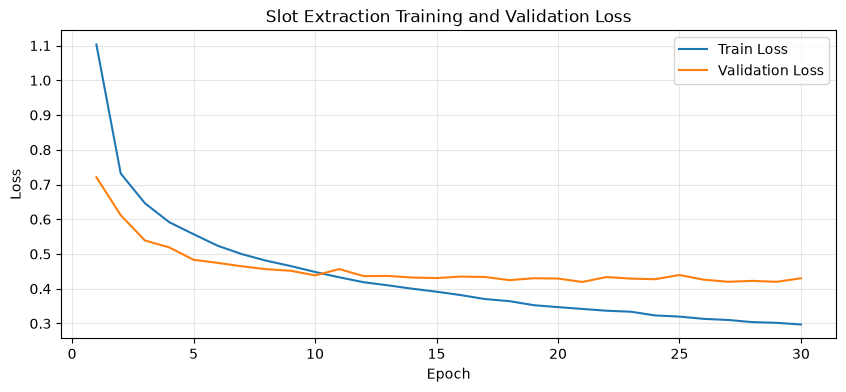

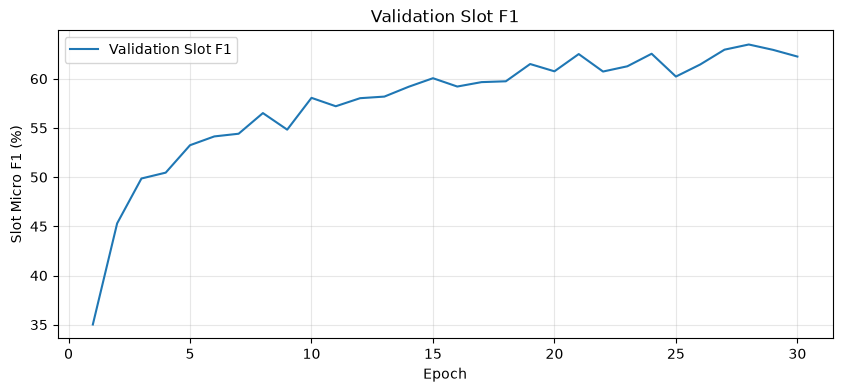

In [57]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 4))
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Slot Extraction Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(epochs, history["val_f1"], label="Validation Slot F1")
plt.xlabel("Epoch")
plt.ylabel("Slot Micro F1 (%)")
plt.title("Validation Slot F1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [58]:
checkpoint = torch.load(
    BEST_SLOT_PATH,
    map_location=device,
    weights_only=True
)

slot_model.load_state_dict(
    checkpoint["model_state_dict"]
)

slot_model.eval()

val_loss, val_metrics = evaluate_slot(
    slot_model,
    val_joint_loader,
    slot_criterion,
    device
)

print("Best checkpoint epoch:", checkpoint["epoch"])
print(f"Saved validation F1: {checkpoint['val_f1']:.2f}%")
print(f"Reloaded validation F1: {val_metrics['f1']:.2f}%")

assert abs(
    checkpoint["val_f1"] - val_metrics["f1"]
) < 1e-5

print("Checkpoint verification passed!")

Best checkpoint epoch: 28
Saved validation F1: 63.48%
Reloaded validation F1: 63.48%
Checkpoint verification passed!


In [59]:
import pandas as pd
import os

results_df = pd.DataFrame({
    "epoch": range(1, len(history["train_loss"]) + 1),
    "train_loss": history["train_loss"],
    "val_loss": history["val_loss"],
    "val_slot_f1": history["val_f1"],
    "epoch_time": history["epoch_time"]
})

history_filename = (
    "slot_mlm_history.csv"
    if USE_MLM
    else "slot_no_mlm_history.csv"
)

results_df.to_csv(
    os.path.join(MODEL_FOLDER, history_filename),
    index=False
)

print("Saved history:", history_filename)

display(results_df.tail())

print("Best epoch:", best_epoch)
print(f"Best validation F1: {best_val_f1:.2f}%")

Saved history: slot_mlm_history.csv


,epoch,train_loss,val_loss,val_slot_f1,epoch_time
25,26,0.313233,0.426027,61.449677,59.749037
26,27,0.310071,0.420033,62.955854,58.818339
27,28,0.303889,0.422605,63.481706,58.978361
28,29,0.301809,0.419886,62.936394,57.668320
29,30,0.297032,0.430089,62.255915,60.186401


Best epoch: 28
Best validation F1: 63.48%


In [60]:
val_loss, val_metrics = evaluate_slot(
    slot_model,
    val_joint_loader,
    slot_criterion,
    device
)

print(f"Slot F1: {val_metrics['f1']:.2f}%")
print("TP:", val_metrics["tp"])
print("FP:", val_metrics["fp"])
print("FN:", val_metrics["fn"])

Slot F1: 63.48%
TP: 1362
FP: 917
FN: 650
